<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/experiment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


Total Dataset Samples: 150
Total Features: 4
Target Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Training Samples: 120
Testing Samples: 30

========== ANN TRAINING COMPLETED ==========
Algorithm: Backpropagation
Input Layer Neurons: 4
Hidden Layer Neurons: 10
Output Classes: 3

========== ACTUAL VS PREDICTED ==========


,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Testing Accuracy: 96.67 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



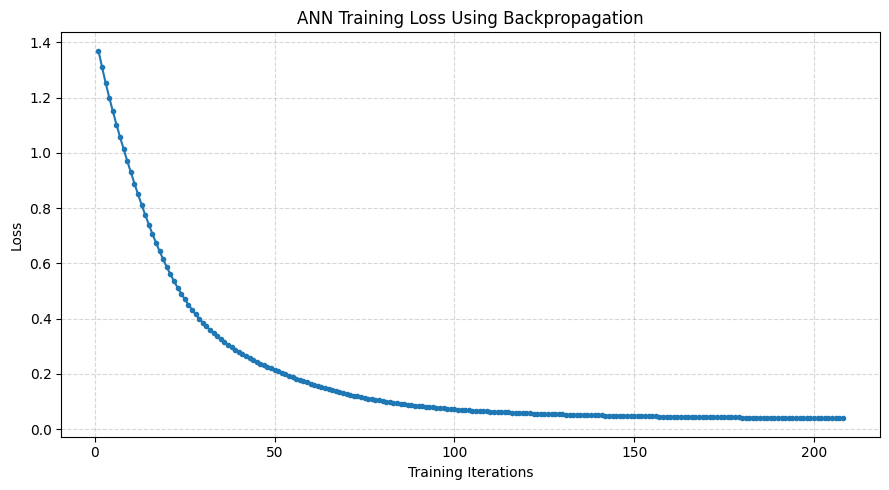

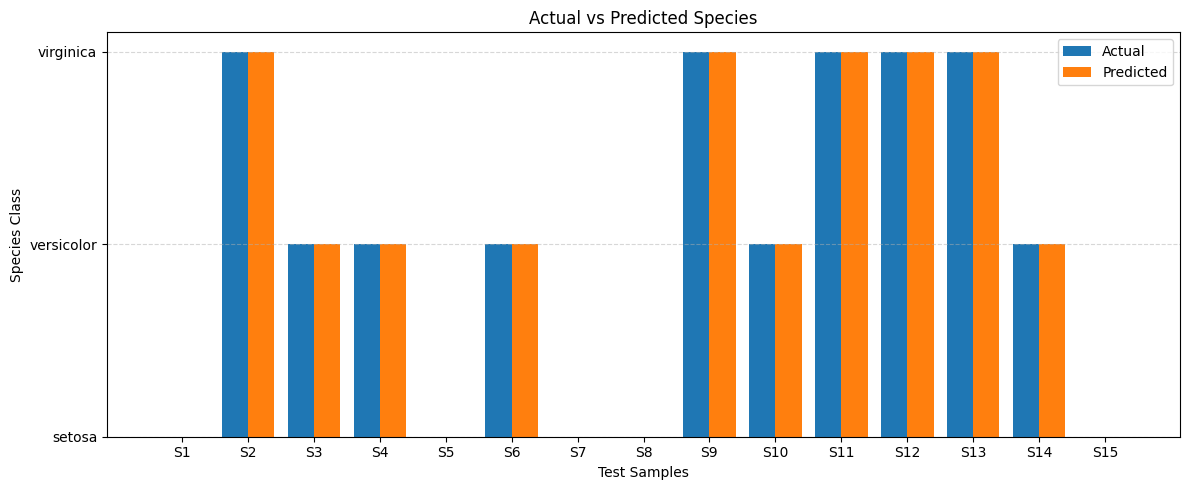

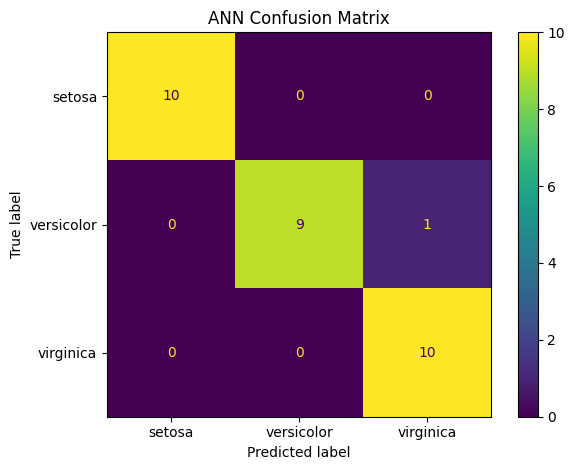

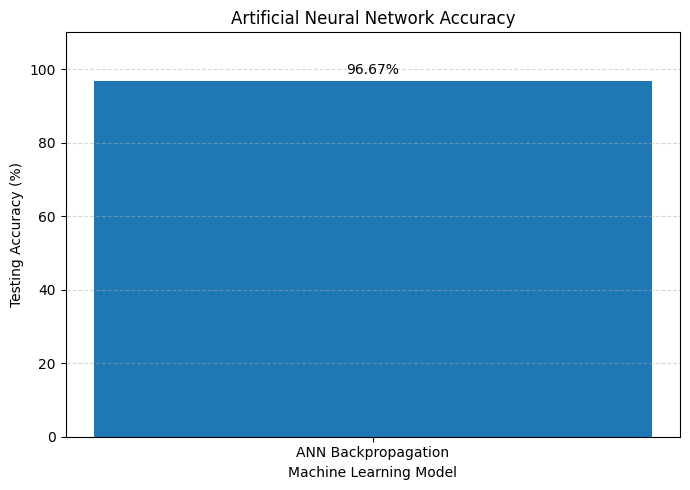


========== FINAL MODEL ==========
Input Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Learned Weights:
[array([[ 0.58288448,  0.00185874, -0.3060794 ,  0.52471168, -1.27474133,
        -0.04972751, -0.26002498,  0.83214156,  0.41191243,  0.7761517 ],
       [-1.36033986,  0.69929351,  0.55386852, -0.68763369, -0.22307943,
        -0.4014117 , -0.4731959 ,  0.3038142 , -0.97858364, -0.74571767],
       [ 1.42585242, -1.05210875, -0.85263681,  0.30604183, -0.66064011,
         1.06001054, -0.0996737 ,  0.45995551,  0.68342197, -0.85792666],
       [ 1.49730659, -1.0028451 , -1.13457016,  0.76470991,  0.05169342,
         1.10741955,  0.03660084, -0.00820307,  0.81853257, -0.91886447]]), array([[ 1.85029834e-01, -5.71387147e-01,  2.03540209e+00],
       [ 9.87342734e-01, -3.50920177e-01,  1.51634278e-01],
       [ 1.85444644e-03, -1.09943368e+00, -1.06730203e+00],
       [-7.06281258e-01,  5.01745414e-01, -4.29558931e-02],
       [ 7.7471090

In [1]:
# EXPERIMENT 4: ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# STEP 1: LOAD THE DATASET
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("========== TRAINING DATASET ==========")
display(df.head(10))

print("Total Dataset Samples:", len(df))
print("Total Features:", X.shape[1])
print("Target Classes:", list(iris.target_names))

# STEP 2: SPLIT THE DATASET
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: FEATURE SCALING
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# STEP 4: CREATE ANN MODEL
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

# STEP 5: TRAIN THE MODEL
model.fit(X_train_scaled, y_train)

print("\n========== ANN TRAINING COMPLETED ==========")
print("Algorithm: Backpropagation")
print("Input Layer Neurons:", X_train.shape[1])
print("Hidden Layer Neurons:", 10)
print("Output Classes:", len(iris.target_names))

# STEP 6: PREDICT TEST DATA
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== ACTUAL VS PREDICTED ==========")

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

display(results)

print("Testing Accuracy:", round(accuracy * 100, 2), "%")

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# STEP 7: TRAINING LOSS GRAPH
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(model.loss_curve_) + 1),
    model.loss_curve_,
    marker='o',
    markersize=3
)

plt.title("ANN Training Loss Using Backpropagation")
plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 8: ACTUAL VS PREDICTED BAR GRAPH
sample_count = min(15, len(y_test))
sample_index = np.arange(sample_count)

plt.figure(figsize=(12, 5))

plt.bar(
    sample_index - 0.2,
    y_test[:sample_count],
    width=0.4,
    label='Actual'
)

plt.bar(
    sample_index + 0.2,
    y_pred[:sample_count],
    width=0.4,
    label='Predicted'
)

plt.title("Actual vs Predicted Species")
plt.xlabel("Test Samples")
plt.ylabel("Species Class")

plt.xticks(
    sample_index,
    [f'S{i+1}' for i in sample_index]
)

plt.yticks(
    [0, 1, 2],
    iris.target_names
)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 9: CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display_matrix.plot()
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 10: ACCURACY BAR GRAPH
plt.figure(figsize=(7, 5))

plt.bar(
    ['ANN Backpropagation'],
    [accuracy * 100]
)

plt.title("Artificial Neural Network Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Testing Accuracy (%)")
plt.ylim(0, 110)

plt.text(
    0,
    accuracy * 100 + 2,
    f'{accuracy * 100:.2f}%',
    ha='center'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: FINAL HYPOTHESIS / LEARNED MODEL
print("\n========== FINAL MODEL ==========")

print("Input Features:", iris.feature_names)
print("Learned Weights:")
print(model.coefs_)

print("\nLearned Biases:")
print(model.intercepts_)

print("\nFinal Testing Accuracy:", round(accuracy * 100, 2), "%")

# STEP 12: TEST A NEW SAMPLE
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])

new_sample_scaled = scaler.transform(new_sample)

new_prediction = model.predict(new_sample_scaled)

print("\n========== NEW SAMPLE PREDICTION ==========")
print("Input:", new_sample[0])
print("Predicted Species:", iris.target_names[new_prediction[0]])

print("\n========== RESULT ==========")
print("ANN with Backpropagation executed successfully.")